AdaGrad Error (MSE): 0.18361620782474167


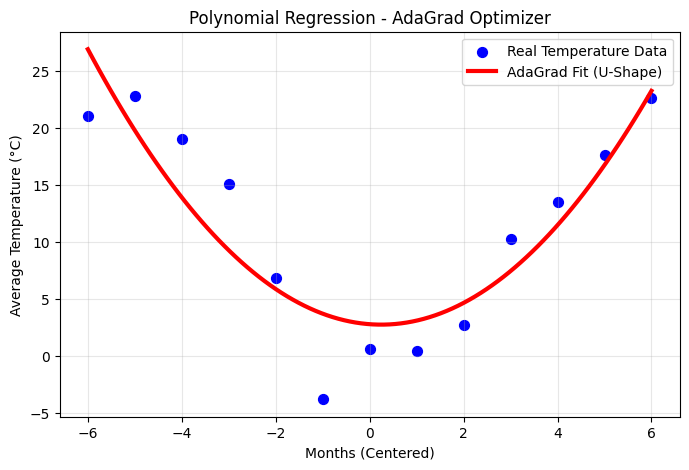

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error

df = pd.read_csv('/kaggle/input/datasets/berkeleyearth/climate-change-earth-surface-temperature-data/GlobalLandTemperaturesByMajorCity.csv')
df = df.dropna()
df_city = df[(df['City'] == 'Chicago') & (df['dt'] >= '2000-07-01') & (df['dt'] <= '2001-07-01')]

X = np.arange(len(df_city)).reshape(-1, 1)
y = df_city['AverageTemperature'].values
X_centered = X - np.mean(X)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_centered)

scaler_X = StandardScaler()
X_poly_scaled = scaler_X.fit_transform(X_poly)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()


adagrad = SGDRegressor(max_iter=3000, learning_rate='adaptive', eta0=0.01, random_state=42)
adagrad.fit(X_poly_scaled, y_scaled)
mse = mean_squared_error(y_scaled, adagrad.predict(X_poly_scaled))
print("AdaGrad Error (MSE):", mse)

plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y, color='blue', s=50, label='Real Temperature Data')
X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_poly = poly.transform(X_grid)
X_grid_poly_scaled = scaler_X.transform(X_grid_poly)
y_pred_scaled = adagrad.predict(X_grid_poly_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
plt.plot(X_grid, y_pred, color='red', linewidth=3, label='AdaGrad Fit (U-Shape)')
plt.xlabel('Months (Centered)')
plt.ylabel('Average Temperature (°C)')
plt.title('Polynomial Regression - AdaGrad Optimizer')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


--- Logistic Regression (AdaGrad) Metrics ---
Log Loss  : 0.2380
Accuracy  : 0.9231
Precision : 1.0000
Recall    : 0.8571
F1-Score  : 0.9231


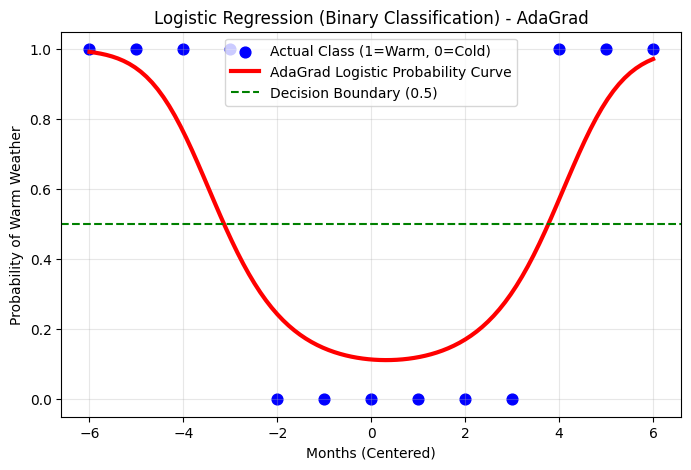

In [2]:
# ==========================================
# Assignment 2: Logistic Regression (AdaGrad)
# ==========================================
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

# 1. تحويل درجات الحرارة إلى تصنيف ثنائي (1 = حار، 0 = بارد)
threshold = np.mean(y)
y_binary = (y > threshold).astype(int)

# 2. بناء وتدريب موديل Logistic Regression باستخدام AdaGrad (Adaptive Learning Rate)
adagrad_clf = SGDClassifier(loss='log_loss', max_iter=3000, learning_rate='adaptive', eta0=0.01, random_state=42)
adagrad_clf.fit(X_poly_scaled, y_binary)

# 3. التوقع وحساب الاحتمالات
y_pred_class = adagrad_clf.predict(X_poly_scaled)
y_pred_prob = adagrad_clf.predict_proba(X_poly_scaled)[:, 1]

# 4. حساب وطباعة المقاييس الخمسة المطلوبة
acc = accuracy_score(y_binary, y_pred_class)
prec = precision_score(y_binary, y_pred_class)
rec = recall_score(y_binary, y_pred_class)
f1 = f1_score(y_binary, y_pred_class)
loss = log_loss(y_binary, y_pred_prob)

print("--- Logistic Regression (AdaGrad) Metrics ---")
print(f"Log Loss  : {loss:.4f}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

# 5. رسم منحنى الاحتمالات
plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y_binary, color='blue', s=60, label='Actual Class (1=Warm, 0=Cold)')

X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_poly = poly.transform(X_grid)
X_grid_poly_scaled = scaler_X.transform(X_grid_poly)
y_grid_prob = adagrad_clf.predict_proba(X_grid_poly_scaled)[:, 1]

plt.plot(X_grid, y_grid_prob, color='red', linewidth=3, label='AdaGrad Logistic Probability Curve')
plt.axhline(0.5, color='green', linestyle='--', label='Decision Boundary (0.5)')
plt.xlabel('Months (Centered)')
plt.ylabel('Probability of Warm Weather')
plt.title('Logistic Regression (Binary Classification) - AdaGrad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
